# *`K-NEAREST NEIGHBOR`*

## ***Step 1: Load and Explore the Dataset***


In [10]:
# Step 1: Load and Explore the Dataset

import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
# Load dataset
data = pd.read_csv("Datasets.csv")

print("Rows:", data.shape[0], "Columns:", data.shape[1])
display(data.head())
display(data.info())
display(data.describe())



Rows: 100 Columns: 3


,Country,Age,Salary
0,India,45.0,70000.0
1,Germany,26.0,56000.0
2,France,46.0,60000.0
3,France,31.0,72000.0
4,India,37.0,96000.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  100 non-null    object 
 1   Age      89 non-null     float64
 2   Salary   88 non-null     float64
dtypes: float64(2), object(1)
memory usage: 2.5+ KB


None

,Age,Salary
count,89.000000,88.000000
mean,42.325843,70204.545455
std,10.151999,16736.057220
min,25.000000,40000.000000
25%,34.000000,56000.000000
50%,41.000000,71000.000000
75%,52.000000,82500.000000
max,59.000000,98000.000000


## ***Step 2: Data Preprocessing***

In [12]:
# Cell 2: Preprocessing - handle missing values, encode labels, normalize numeric features

# 1) Handle missing values (avoid inplace on column to remove FutureWarning)
data = data.copy()  # work on an explicit copy to be safe
data["Age"] = data["Age"].fillna(data["Age"].mean())
data["Salary"] = data["Salary"].fillna(data["Salary"].mean())

# 2) Encode 'Country' column and keep mapping (so we can show readable labels later)
encoder = LabelEncoder()
data["Country_encoded"] = encoder.fit_transform(data["Country"])
country_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
inverse_country_mapping = {v: k for k, v in country_mapping.items()}

print("Country mapping (string -> int):", country_mapping)

# 3) Normalize numerical columns using MinMax scaling
scaler = MinMaxScaler()
data[["Age_norm", "Salary_norm"]] = scaler.fit_transform(data[["Age", "Salary"]])

# Show processed data
display(data.head())


Country mapping (string -> int): {'France': 0, 'Germany': 1, 'India': 2}


,Country,Age,Salary,Country_encoded,Age_norm,Salary_norm
0,India,45.0,70000.0,2,0.588235,0.517241
1,Germany,26.0,56000.0,1,0.029412,0.275862
2,France,46.0,60000.0,0,0.617647,0.344828
3,France,31.0,72000.0,0,0.176471,0.551724
4,India,37.0,96000.0,2,0.352941,0.965517


## ***Step3:Splitting the data into training and testing data***

In [15]:
# For this assignment we'll predict 'Country' (classification) using Age and Salary.
X = data[["Age_norm", "Salary_norm"]].values   # features (2D)
y = data["Country_encoded"].astype(int).values # integer labels
# Stratify by y to keep class distribution in both sets (safe when classes exist)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])


Train size: 80 Test size: 20


## ***Step 4:Implementing the KNN from scratch***

In [18]:
def euclidean_distance(a, b):
    """Return Euclidean distance between two 1-D arrays."""
    return np.sqrt(np.sum((a - b) ** 2))

def knn_predict(X_train, y_train, X_test, k=3):
    """
    Predict labels for X_test using k-NN from scratch.
    - X_train: numpy array shape (n_train, n_features)
    - y_train: numpy array shape (n_train,)
    - X_test : numpy array shape (n_test, n_features)
    Returns: numpy array of predicted labels for X_test
    """
    preds = []
    for i, test_point in enumerate(X_test):
        # Compute all distances to training points
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        # Indices of k smallest distances
        k_idx = np.argsort(distances)[:k]
        # Labels of nearest neighbors
        k_labels = y_train[k_idx]
        # Majority vote (if tie, Counter.most_common returns one of the top)
        most_common_label = Counter(k_labels).most_common(1)[0][0]
        preds.append(most_common_label)
    return np.array(preds)

## ***Step5:Predcit and evaluate***

In [21]:
k = 5  # you can change k to experiment
y_pred = knn_predict(X_train, y_train, X_test, k=k)
# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"K={k}  Accuracy: {acc:.4f}")
# Confusion matrix (with readable labels)
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
                     index=[inverse_country_mapping[i] for i in range(cm.shape[0])],
                     columns=[inverse_country_mapping[i] for i in range(cm.shape[1])])
print("\nConfusion Matrix (rows=true, cols=predicted):")
display(cm_df)

K=5  Accuracy: 0.3500

Confusion Matrix (rows=true, cols=predicted):


,France,Germany,India
France,3,1,2
Germany,2,3,2
India,2,4,1


## ***Step 6:Simple vizualization of the test points and Predicted labels***

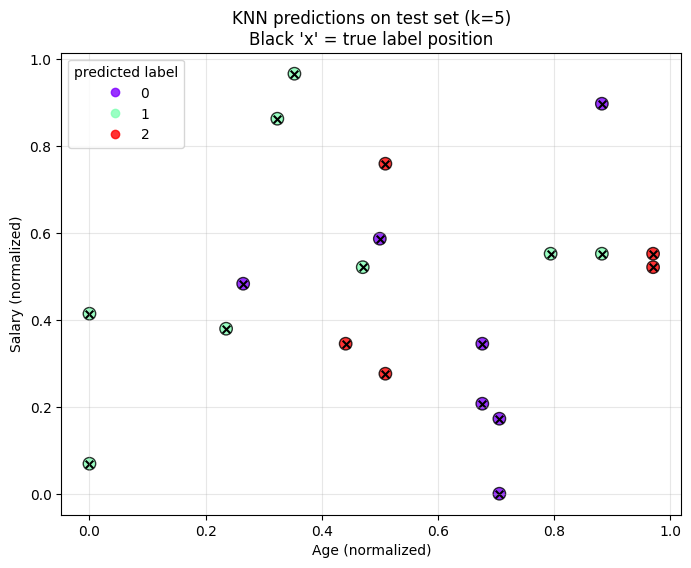

In [25]:
# Cell 6: Scatter plot of test points colored by predicted label (and marker for true labels)

plt.figure(figsize=(8,6))
# Plot test points colored by predicted label
scatter = plt.scatter(X_test[:,0], X_test[:,1], c=y_pred, s=80, cmap='rainbow', alpha=0.8, edgecolors='k', label='predicted')

# Optionally mark true labels with smaller cross markers
for i, (xpt, ypt) in enumerate(X_test):
    true_label = y_test[i]
    plt.scatter(xpt, ypt, marker='x', c='black', s=30)

plt.xlabel("Age (normalized)")
plt.ylabel("Salary (normalized)")
plt.title(f"KNN predictions on test set (k={k})\nBlack 'x' = true label position")
plt.legend(*scatter.legend_elements(), title="predicted label")
plt.grid(alpha=0.3)
plt.show()
